## Event Streaming

In [6]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model

model = init_chat_model(
    model="deepseek-v4-flash",
    extra_body={"thinking": {"type": "disabled"}} # 指定思考模式 "enabled"、"disabled"
)

def get_weather(city: str) -> str:
    """Get weather for a city."""
    return f"It's always sunny in {city}!"

agent = create_agent(
    model=model,
    tools=[get_weather],
)

stream = agent.stream_events(
    {"messages": [{"role": "user", "content": "What is the weather in SF?"}]},
    version="v3"
)

for message in stream.messages:
    for delta in message.text:
        print(delta, end="", flush=True)

final_state = stream.output

It's always sunny in San Francisco! ☀️

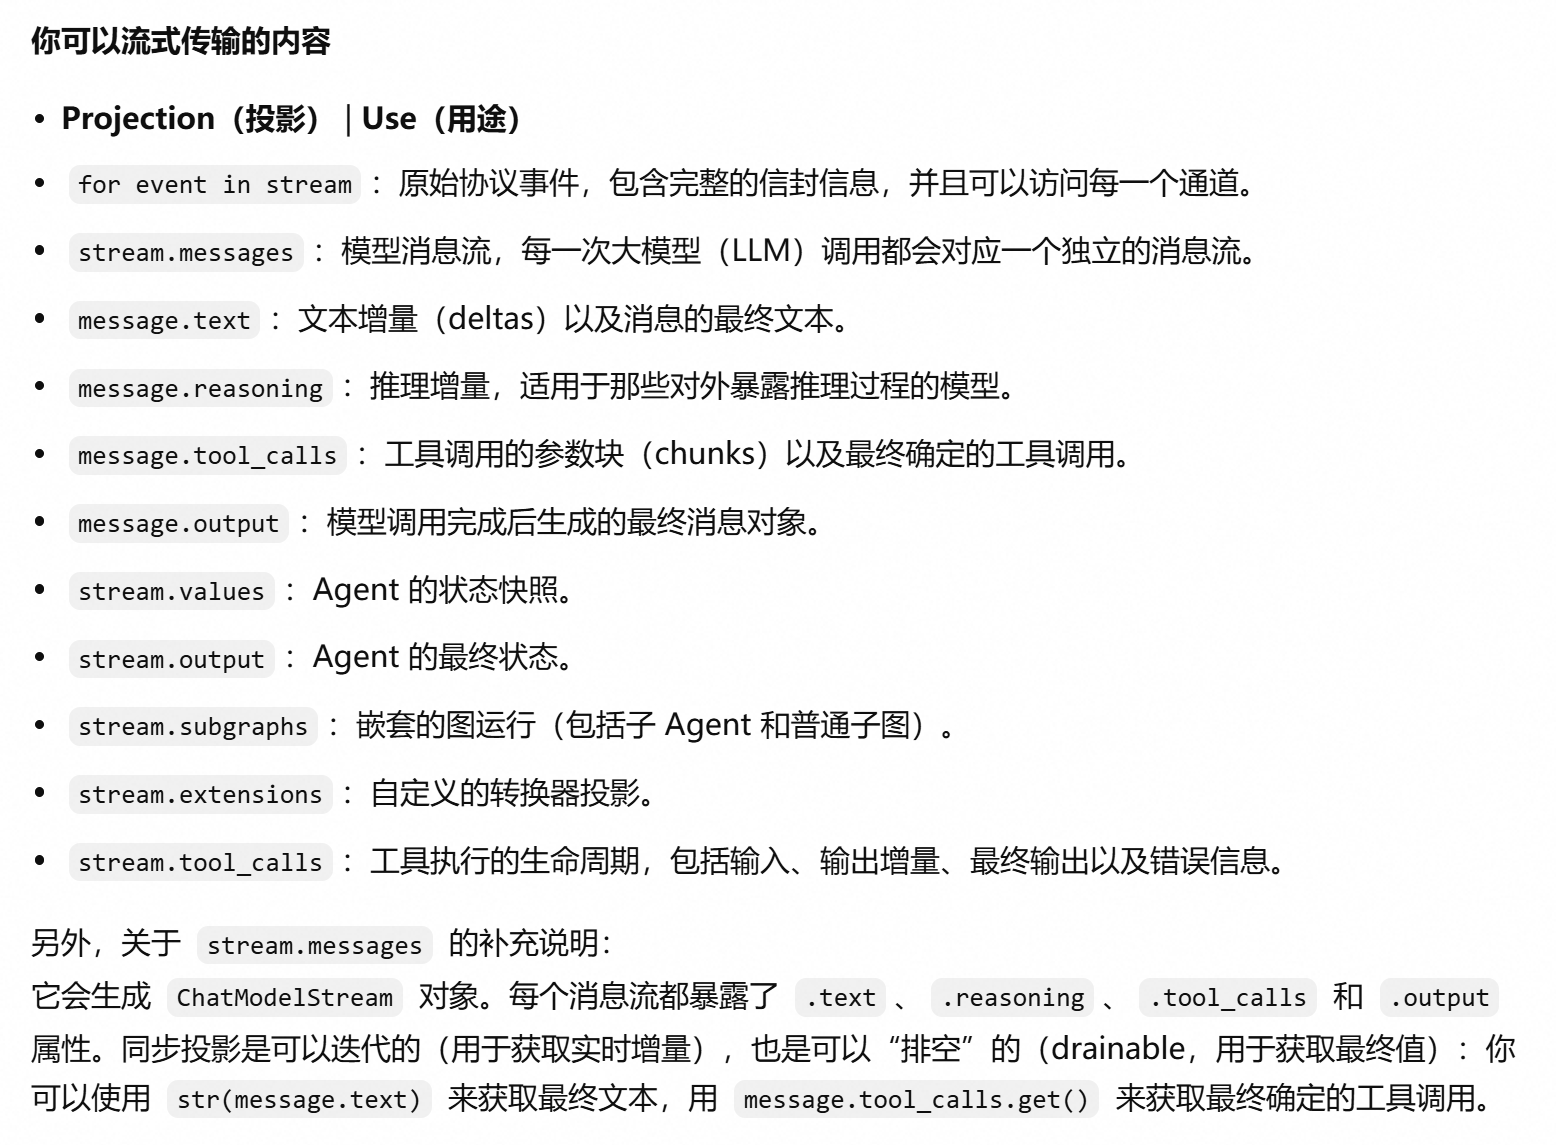